# SCC0957 — Prática de Ciências de Dados II: Dados da Dengue PySuS
* Vinícius de Moraes - 13749910
* Rômulo Ferreira da Silva - 13734326
* João Pedro Barbosa Madeira - 13683038
* Pedro Silva dos Santos - 12688431
* Thiago Pasquotto Tavares - 15490194

## Carregando as bibliotecas

In [98]:
!uv pip install pysus==1.0.1 -q
!uv pip install nbformat
!uv pip install plotly
!uv pip install matplotlib
!uv pip install geopandas
!uv pip install requests
!uv pip install polars

Using Python 3.12.14 environment at: /home/boemio/Projects/.venv
Checked 1 package in 7ms
Using Python 3.12.14 environment at: /home/boemio/Projects/.venv
Checked 1 package in 2ms
Using Python 3.12.14 environment at: /home/boemio/Projects/.venv
Checked 1 package in 6ms
Using Python 3.12.14 environment at: /home/boemio/Projects/.venv
Checked 1 package in 3ms
Using Python 3.12.14 environment at: /home/boemio/Projects/.venv
Checked 1 package in 4ms
Using Python 3.12.14 environment at: /home/boemio/Projects/.venv
Checked 1 package in 4ms


In [99]:
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import plotly.express as px
from pysus import SINAN
import polars as pl
import geopandas as gpd
import requests
from pysus.online_data import IBGE

## Carregando os dados

### 1. Carregando os Dados do SINAN

In [100]:
sinan = SINAN().load() # Loads the files from DATASUS
files = sinan.get_files(dis_code=["DENG"])
parquet = sinan.download(files)

24049349it [00:00, 2681008949.29it/s] 


In [101]:
df = pl.scan_parquet(
    [str(p) for p in parquet],
    extra_columns="ignore",
    missing_columns="insert"
)

### 2. Carregando os Dados Geográficos do Geodata

In [102]:
url = "https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-100-mun.json"

gdf = gpd.read_file(url)

gdf['latitude'] = gdf.geometry.centroid.y
gdf['longitude'] = gdf.geometry.centroid.x

gdf

/tmp/ipykernel_2179228/2435523726.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['latitude'] = gdf.geometry.centroid.y
/tmp/ipykernel_2179228/2435523726.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf['longitude'] = gdf.geometry.centroid.x


,id,name,description,geometry,latitude,longitude
0,1100015,Alta Floresta D'Oeste,Alta Floresta D'Oeste,"POLYGON ((-62.18209 -11.86686, -62.1623 -11.87...",-12.469633,-62.274095
1,1100023,Ariquemes,Ariquemes,"POLYGON ((-62.53595 -9.73182, -62.50782 -9.754...",-9.951564,-62.956923
2,1100031,Cabixi,Cabixi,"POLYGON ((-60.3994 -13.45584, -60.40195 -13.46...",-13.474432,-60.639192
3,1100049,Cacoal,Cacoal,"POLYGON ((-61.00051 -11.39796, -61.01794 -11.4...",-11.300812,-61.324237
4,1100056,Cerejeiras,Cerejeiras,"POLYGON ((-61.50047 -13.00392, -61.47901 -13.0...",-13.203228,-61.260380
...,...,...,...,...,...,...
5559,5222005,Vianópolis,Vianópolis,"POLYGON ((-48.43125 -16.62755, -48.42527 -16.6...",-16.812518,-48.441465
5560,5222054,Vicentinópolis,Vicentinópolis,"POLYGON ((-49.85005 -17.57682, -49.84311 -17.5...",-17.724391,-49.872132
5561,5222203,Vila Boa,Vila Boa,"POLYGON ((-47.11019 -14.6715, -47.11607 -14.67...",-14.992990,-47.062354
5562,5222302,Vila Propício,Vila Propício,"POLYGON ((-48.75124 -14.90461, -48.75196 -14.9...",-15.268832,-48.814195


### 3. Carregando os dados de população do IBGE

In [103]:
census = IBGE.get_population(year=2010)

In [104]:
gdf['id_6'] = gdf['id'].astype(str).str[:-1]
census = census.merge(
    gdf[['id_6', 'name']],
    left_on='MUNIC_RES',
    right_on='id_6',
    how='left'
)

census.drop(labels='id_6', axis=1, inplace=True)

In [105]:
gdf['UF_cod'] = gdf['id_6'].str[:2].astype(int)

cod_to_uf = {
    11:'RO',12:'AC',13:'AM',14:'RR',15:'PA',16:'AP',17:'TO',
    21:'MA',22:'PI',23:'CE',24:'RN',25:'PB',26:'PE',27:'AL',28:'SE',29:'BA',
    31:'MG',32:'ES',33:'RJ',35:'SP',
    41:'PR',42:'SC',43:'RS',
    50:'MS',51:'MT',52:'GO',53:'DF'
}

gdf['UF'] = gdf['UF_cod'].map(cod_to_uf)

census = census.merge(
    gdf[['id_6', 'UF']],
    left_on='MUNIC_RES',
    right_on='id_6',
    how='left'
)

census.drop(columns=['id_6'], inplace=True)

In [106]:
census = census.drop_duplicates(subset='name')

In [107]:
census

,MUNIC_RES,ANO,POPULACAO,name,UF
0,110001,2010,24422,Alta Floresta D'Oeste,RO
1,110002,2010,90354,Ariquemes,RO
2,110003,2010,6309,Cabixi,RO
3,110004,2010,78601,Cacoal,RO
4,110005,2010,17030,Cerejeiras,RO
...,...,...,...,...,...
5560,522200,2010,12549,Vianópolis,GO
5561,522205,2010,7371,Vicentinópolis,GO
5562,522220,2010,4742,Vila Boa,GO
5563,522230,2010,5145,Vila Propício,GO


## Preparando os dados 

In [108]:
df_sp = (
    df
    .filter(pl.col("SG_UF_NOT").is_in(["35", "SP"]))
    .filter(pl.col("UF").is_in(["35", "SP"]))
    .collect()
    .to_pandas()
)

df_sp

,ID_MUNICIP,ID_UNIDADE,DT_NOTIFIC,CS_RACA,CS_ESCOLAR,NU_ANO,SEM_NOT,SG_UF_NOT,ID_REGIONA,DT_SIN_PRI,...,CON_INF_MU,CON_INF_UF,CON_INF_PA,CON_DOENCA,CON_EVOLUC,CON_DT_OBI,CON_DT_ENC,IN_VINCULA,NDUPLIC,IN_AIDS
0,3537305,2043904,20031114,1,4,2003,462003,SP,006,20031020,...,,,,2,1,,20031224,,0,
1,3523107,2078562,20031003,1,2,2003,402003,SP,003,20030928,...,3523107,SP,800,2,1,,20031023,,0,
2,3534401,2079887,20030127,1,3,2003,052003,SP,005,20030119,...,,,,2,1,,20030207,,,
3,3522505,3368122,20030121,9,9,2003,042003,SP,005,20030114,...,3522505,SP,800,2,1,,20030130,,,
4,3522505,2093189,20030130,2,1,2003,052003,SP,005,20030124,...,,,,2,1,,20030207,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160501,354980,2797844,20260510,1,None,2026,202619,35,1354,20260507,...,None,None,None,None,None,None,None,None,None,None
160502,350410,2078228,20260223,1,None,2026,202608,35,1342,20260223,...,None,None,None,None,None,None,None,None,None,None
160503,354340,7965192,20260720,1,None,2026,202629,35,1348,20260708,...,None,None,None,None,None,None,None,None,None,None
160504,354980,2077396,20260503,4,None,2026,202618,35,1354,20260501,...,None,None,None,None,None,None,None,None,None,None


In [109]:
df_sp_confirmed = (
    df
    .filter(pl.col("SG_UF_NOT").is_in(["35", "SP"]))
    .filter(pl.col("UF").is_in(["35", "SP"]))
    .filter(pl.col("DENGUE").is_in(["1","2"]))
    .sort("DT_NOTIFIC")
    .collect()
    .to_pandas()
)

df_sp_confirmed

,ID_MUNICIP,ID_UNIDADE,DT_NOTIFIC,CS_RACA,CS_ESCOLAR,NU_ANO,SEM_NOT,SG_UF_NOT,ID_REGIONA,DT_SIN_PRI,...,CON_INF_MU,CON_INF_UF,CON_INF_PA,CON_DOENCA,CON_EVOLUC,CON_DT_OBI,CON_DT_ENC,IN_VINCULA,NDUPLIC,IN_AIDS
0,3548906,2071967,20030102,1,3,2003,012003,SP,007,20021227,...,,,,2,1,,20030122,,,
1,3549250,2051451,20030102,1,3,2003,012003,SP,022,20021230,...,3549201,SP,800,9,1,,20030205,,,
2,3550308,3212130,20030102,1,6,2003,012003,SP,001,20021225,...,3550308,SP,800,2,1,,20030106,,,
3,3550308,2089580,20030102,9,9,2003,012003,SP,001,20021223,...,3509502,SP,800,2,1,,20030109,,,
4,3518206,2063824,20030102,3,1,2003,012003,SP,006,20021226,...,3518206,SP,800,2,1,,20030110,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10473,3552403,2047888,20061230,4,2,2006,522006,SP,012,20061225,...,3552403,SP,800,2,1,,20070116,,0,
10474,3509502,2078465,20061230,1,4,2006,522006,SP,012,20061224,...,3509502,SP,800,2,1,,20070116,,0,
10475,3556305,2081105,20061231,1,3,2006,012007,SP,006,20061223,...,3556305,SP,800,2,1,,20061231,,0,
10476,3509502,2081946,20061231,1,5,2006,012007,SP,012,20061229,...,3509502,SP,800,2,1,,20070116,,0,


**Notificações**

In [110]:
result = (
    df
    .filter(pl.col("SG_UF_NOT").is_in(["35", "SP"]))
    .filter(pl.col("UF").is_in(["35", "SP"]))
    .group_by("DT_NOTIFIC")
    .agg(pl.len().alias("Notificações"))
    .rename({"DT_NOTIFIC": "Dia"})
    .sort("Dia")
)

df_notificacoes = result.collect().to_pandas()

df_notificacoes['Dia'] = pd.to_datetime(df_notificacoes['Dia'], format='%Y%m%d', errors='coerce')

df_notificacoes = df_notificacoes.dropna(subset=['Dia'])

df_notificacoes

,Dia,Notificações
0,2003-01-02,6
1,2003-01-03,12
2,2003-01-04,2
3,2003-01-06,15
4,2003-01-07,13
...,...,...
6727,2026-09-08,12
6728,2026-09-09,10
6729,2026-09-10,7
6730,2026-09-11,10


**Sazonalidade dos dados**

In [111]:
df_notificacoes["Ano"] = df_notificacoes["Dia"].dt.year
df_notificacoes["Mês"] = df_notificacoes["Dia"].dt.month

df_sazonalidade = (
    df_notificacoes
    .groupby(["Ano", "Mês"])["Notificações"]
    .mean()
    .reset_index()
)

df_sazonalidade

,Ano,Mês,Notificações
0,2003,1,10.464286
1,2003,2,16.285714
2,2003,3,22.741935
3,2003,4,15.857143
4,2003,5,8.758621
...,...,...,...
279,2026,5,16.000000
280,2026,6,7.566667
281,2026,7,6.931034
282,2026,8,6.758621


**Classificação final da doença**

In [112]:
classi_fin = (
    df
    .select("DENGUE")
    .collect()
    .to_pandas()
)

classi_fin = (
    df
    .filter(pl.col("SG_UF_NOT").is_in(["35", "SP"]))
    .filter(pl.col("UF").is_in(["35", "SP"]))
    .select(
        pl.col("DENGUE")
        .str.strip_chars()
        .replace({
            "9": "Ignorado",
            "8": "Inconclusivo",
            "1": "Positivo",
            "2": "Negativo",
            "": "Ignorado"
        })
        .fill_null("Não preenchido")
        .alias("DENGUE")
    )
    .collect()
    .to_pandas()
)

print(classi_fin['DENGUE'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')
classi_fin

DENGUE
Não preenchido    92.53%
Negativo           6.25%
Ignorado           0.94%
Positivo           0.28%
Name: proportion, dtype: object


,DENGUE
0,Negativo
1,Negativo
2,Negativo
3,Negativo
4,Negativo
...,...
160501,Não preenchido
160502,Não preenchido
160503,Não preenchido
160504,Não preenchido


**Notificações por sexo**

In [113]:
cs_sexo = (
    df
    .filter(pl.col("SG_UF_NOT").is_in(["35", "SP"]))
    .filter(pl.col("UF").is_in(["35", "SP"]))
    .select(
        pl.col("CS_SEXO")
        .str.strip_chars()
        .replace({
            'M': 'Masculino',
            'F': 'Feminino',
            'I': 'Ignorado',
            '' : 'Ignorado',
            'O': 'Ignorado'
        })
        .fill_null("Não preenchido")
        .alias("CS_SEXO")
    )
    .collect()
    .to_pandas()
)

print(cs_sexo['CS_SEXO'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')
cs_sexo

CS_SEXO
Feminino     52.97%
Masculino    46.98%
Ignorado      0.05%
Name: proportion, dtype: object


,CS_SEXO
0,Feminino
1,Masculino
2,Masculino
3,Masculino
4,Masculino
...,...
160501,Masculino
160502,Masculino
160503,Masculino
160504,Masculino


**Notificações por raça/etnia**

In [114]:
cs_raca = (
    df
    .filter(pl.col("SG_UF_NOT").is_in(["35", "SP"]))
    .filter(pl.col("UF").is_in(["35", "SP"]))
    .select(
        pl.col("CS_RACA")
        .str.strip_chars()
        .replace({
            '': 'Ignorado',
            '1': 'Branca',
            '2': 'Preta',
            '3': 'Amarela',
            '4': 'Parda',
            '5': 'Indígena',
            '9': 'Ignorado',
            '@': 'Ignorado'
        })
        .fill_null("Não preenchido")
        .alias("CS_RACA")
    )
    .collect()
    .to_pandas()
)

print(cs_raca['CS_RACA'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')
cs_raca

CS_RACA
Branca      64.45%
Ignorado    15.75%
Parda        15.2%
Preta        3.22%
Amarela      1.31%
Indígena     0.08%
Name: proportion, dtype: object


,CS_RACA
0,Branca
1,Branca
2,Branca
3,Ignorado
4,Preta
...,...
160501,Branca
160502,Branca
160503,Branca
160504,Parda


**Evolução dos casos**

In [115]:
df_evolucao = (
    df
    .filter(pl.col("SG_UF_NOT").is_in(["35", "SP"]))
    .filter(pl.col("UF").is_in(["35", "SP"]))
    .select(
        pl.col('CON_EVOLUC')
        .str.strip_chars()
        .replace({
            '0': 'não se aplica',
            '1': 'cura',
            '2': 'óbito pelo agravo',
            '3': 'óbito por outras causas',
            '4': 'óbito em investigação',
            '9': 'ignorado',
            '': 'ignorado',
            ']': 'ignorado'
        })
        .fill_null('Não preenchido')
        .alias('CON_EVOLUC')
    )
    .collect()
    .to_pandas()
)

print(df_evolucao['CON_EVOLUC'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')
df_evolucao

CON_EVOLUC
Não preenchido       92.53%
cura                  6.21%
ignorado              1.06%
óbito pelo agravo      0.2%
não se aplica          0.0%
Name: proportion, dtype: object


,CON_EVOLUC
0,cura
1,cura
2,cura
3,cura
4,cura
...,...
160501,Não preenchido
160502,Não preenchido
160503,Não preenchido
160504,Não preenchido


**Número de notificações por estado**

In [116]:
df_estado = (
    df
    .filter(pl.col("SG_UF_NOT").is_in(["35", "SP"]))
    .filter(pl.col("UF").is_in(["35", "SP"]))
    .with_columns(
        pl.col("UF")
        .cast(pl.String)
        .str.strip_chars()
        .replace({
            "35": "SP",
            "0": None,
            "": None,
            "`": None
        })
    )
    .drop_nulls("UF")
    .group_by("UF")
    .agg(pl.len().alias("Notificações"))
    .rename({"UF": "Estado"})
    .sort("Estado")
    .collect()
    .to_pandas()
)

df_estado

,Estado,Notificações
0,SP,160506


**Número de notificações por município** 

In [117]:
gdf['id_6'] = gdf['id'].astype(str).str[:-1]
df_sp['ID_MUNICIP'] = df_sp['ID_MUNICIP'].apply(
    lambda x: x[:-1] if len(str(x)) == 7 else x
)

df_municipio = (
    df_sp
    .merge(
        gdf[['id_6', 'name', 'latitude', 'longitude']],
        left_on='ID_MUNICIP',
        right_on='id_6',
        how='left'
    )
    .groupby(['name', 'latitude', 'longitude'])
    .size()
    .reset_index(name='Notificações')
    .dropna(subset=['name'])
)

df_municipio

,name,latitude,longitude,Notificações
0,Adamantina,-21.576304,-51.056162,480
1,Adolfo,-21.288078,-49.652815,12
2,Aguaí,-22.049605,-47.039711,58
3,Agudos,-22.571082,-49.107905,91
4,Alambari,-23.548612,-47.868336,4
...,...,...,...,...
621,Águas de São Pedro,-22.599020,-47.875982,11
622,Álvares Florence,-20.289139,-49.919608,10
623,Álvares Machado,-22.131589,-51.514721,32
624,Álvaro de Carvalho,-22.086286,-49.733313,5


**Número de notificações por município por 100 mil habitantes**

In [118]:
df_municipio_relativo = df_municipio.merge(census[['POPULACAO', 'name']], on='name', how='left')

df_municipio_relativo['POPULACAO'] = (
    df_municipio_relativo['POPULACAO']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '', regex=False)
)

df_municipio_relativo['POPULACAO'] = pd.to_numeric(df_municipio_relativo['POPULACAO'], errors='coerce')

df_municipio_relativo = df_municipio_relativo.dropna(subset=['POPULACAO'])

df_municipio_relativo['taxa_100k'] = (df_municipio_relativo['Notificações'] / df_municipio_relativo['POPULACAO']) * 100000

df_municipio_relativo

,name,latitude,longitude,Notificações,POPULACAO,taxa_100k
0,Adamantina,-21.576304,-51.056162,480,33797,1420.244400
1,Adolfo,-21.288078,-49.652815,12,3557,337.362946
2,Aguaí,-22.049605,-47.039711,58,32168,180.303407
3,Agudos,-22.571082,-49.107905,91,34532,263.523688
4,Alambari,-23.548612,-47.868336,4,4886,81.866558
...,...,...,...,...,...,...
621,Águas de São Pedro,-22.599020,-47.875982,11,2703,406.955235
622,Álvares Florence,-20.289139,-49.919608,10,3901,256.344527
623,Álvares Machado,-22.131589,-51.514721,32,23506,136.135455
624,Álvaro de Carvalho,-22.086286,-49.733313,5,4650,107.526882


## Visualizações

In [119]:
media = df_notificacoes['Notificações'].mean()

fig = px.line(
    df_notificacoes,
    x='Dia',
    y='Notificações'
)

fig.add_hline(
    y=media,
    line_dash='dash',
    annotation_text=f"Média: {media:.0f}",
    annotation_position="top left"
)

fig.update_traces(line=dict(width=1))

fig.show()

In [120]:
fig = px.line(
    df_sazonalidade,
    x="Mês",
    y="Notificações",
    color="Ano",
    markers=True,
    labels={
        "Mês": "Mês",
        "Notificações": "Notificações",
        "Ano": "Ano"
    },
    title="Sazonalidade das notificações por ano em São Paulo"
)

fig.update_layout(
    xaxis=dict(
        tickmode="array",
        tickvals=list(range(1, 13)),
        ticktext=[
            "Jan", "Fev", "Mar", "Abr",
            "Mai", "Jun", "Jul", "Ago",
            "Set", "Out", "Nov", "Dez"
        ]
    )
)

fig.show()

In [121]:
from plotly.subplots import make_subplots

# Criar ano e mês
df_notificacoes["Ano"] = df_notificacoes["Dia"].dt.year
df_notificacoes["Mês"] = df_notificacoes["Dia"].dt.month

# Soma das notificações de cada mês de cada ano
df_mensal = (
    df_notificacoes
    .groupby(["Ano", "Mês"])["Notificações"]
    .sum()
    .reset_index()
)

nomes_meses = [
    "Janeiro", "Fevereiro", "Março", "Abril",
    "Maio", "Junho", "Julho", "Agosto",
    "Setembro", "Outubro", "Novembro", "Dezembro"
]

# Criar 12 gráficos
fig = make_subplots(
    rows=4,
    cols=3,
    subplot_titles=nomes_meses
)

for mes in range(1, 13):

    dados = df_mensal[df_mensal["Mês"] == mes]

    # Média histórica daquele mês
    media = dados["Notificações"].mean()

    linha = go.Scatter(
        x=dados["Ano"],
        y=dados["Notificações"],
        mode="lines+markers",
        name="Notificações",
        showlegend=False
    )

    media_linha = go.Scatter(
        x=dados["Ano"],
        y=[media] * len(dados),
        mode="lines",
        name="Média",
        line=dict(dash="dash"),
        showlegend=False
    )

    linha_idx = (mes - 1) // 3 + 1
    coluna_idx = (mes - 1) % 3 + 1

    fig.add_trace(
        linha,
        row=linha_idx,
        col=coluna_idx
    )

    fig.add_trace(
        media_linha,
        row=linha_idx,
        col=coluna_idx
    )

fig.update_layout(
    title="Tendência das notificações por mês ao longo dos anos em São Paulo",
    height=900,
    width=1200
)

fig.show()

In [122]:
# Contagem dos resultados
dengue_counts = (
    classi_fin["DENGUE"]
    .value_counts()
    .reset_index()
)

dengue_counts.columns = ["Resultado", "Contagem"]

fig = px.bar(
    dengue_counts,
    x="Resultado",
    y="Contagem",
    text="Contagem",
    title="Número de casos de Dengue em São Paulo(2000-2026)",
    labels={
        "Contagem": "Número de casos",
        "Resultado": "Resultado"
    },
    color="Resultado"
)

fig.update_traces(textposition="outside")

fig.show()

In [123]:
# Contagem dos resultados
sexo_counts = (
    cs_sexo["CS_SEXO"]
    .value_counts()
    .reset_index()
)

sexo_counts.columns = ["Sexo", "Contagem"]

fig = px.bar(
    sexo_counts,
    x="Sexo",
    y="Contagem",
    text="Contagem",
    title="Número de casos de Dengue por Sexo em São Paulo(2000-2026)",
    labels={
        "Contagem": "Número de casos",
        "Sexo": "Sexo"
    },
    color="Sexo"
)

fig.update_traces(textposition="outside")

fig.show()

In [124]:
# Contagem dos resultados
raca_counts = (
    cs_raca["CS_RACA"]
    .value_counts()
    .reset_index()
)

raca_counts.columns = ["Raça", "Contagem"]

fig = px.bar(
    raca_counts,
    x="Raça",
    y="Contagem",
    text="Contagem",
    title="Número de casos de Dengue por Raça em São Paulo (2000-2026)",
    labels={
        "Contagem": "Número de casos",
        "Raça": "Raça"
    },
    color="Raça"
)

fig.update_traces(textposition="outside")

fig.show()

In [125]:
# Contagem dos resultados
evolucao_counts = (
    df_evolucao["CON_EVOLUC"]
    .value_counts()
    .reset_index()
)

evolucao_counts.columns = ["Evolução", "Contagem"]

fig = px.bar(
    evolucao_counts,
    x="Evolução",
    y="Contagem",
    text="Contagem",
    title="Evolução dos casos de Dengue em São Paulo (2000-2026)",
    labels={
        "Contagem": "Número de casos",
        "Evolução": "Evolução"
    },
    color="Evolução"
)

fig.update_traces(textposition="outside")

fig.show()

In [126]:
fig = px.scatter_map(
    df_municipio,
    lat='latitude',
    lon='longitude',
    size='Notificações',
    hover_name='name',
    size_max=30,
    zoom=3,
    map_style="carto-positron",
    title='Número de notificações de Dengue por município de São Paulo (2000-2026)',
    height=800
)

fig.update_traces(marker=dict(color='red'))

fig.show()

In [127]:
fig = px.scatter_map(
    df_municipio_relativo,
    lat='latitude',
    lon='longitude',
    size='taxa_100k',
    hover_name='name',
    hover_data={
        'Notificações': True,
        'POPULACAO': True,
        'taxa_100k': ':.2f'
    },
    size_max=30,
    zoom=3,
    map_style="carto-positron",
    title='Taxa de casos de Dengue por 100 mil habitantes em São Paulo'
)

fig.update_traces(marker=dict(color='red'))

fig.update_layout(
    width=1200,
    height=800
)

fig.show()

In [128]:
top_mun = df_municipio.sort_values(
    'Notificações',
    ascending=False
).head(10)

top_mun['Notificações'] = top_mun['Notificações'].astype(float)

fig = px.bar(
    top_mun.sort_values('Notificações'),
    x='Notificações',
    y='name',
    orientation='h',
    text='Notificações',
    title='Top 10 municípios de São Paulo com mais notificações de Dengue (2000-2026)',
    labels={
        'Notificações': 'Número de notificações',
        'name': 'Município'
    },
    color='Notificações'
)

fig.update_traces(textposition='outside')

fig.show()

In [129]:
top_mun_relativo = df_municipio_relativo.sort_values(
    'taxa_100k',
    ascending=False
).head(10)

fig = px.bar(
    top_mun_relativo.sort_values('taxa_100k'),
    x='taxa_100k',
    y='name',
    orientation='h',
    text=top_mun_relativo['taxa_100k'].round(2),
    title='Top 10 municípios de São Paulo com mais casos por 100 mil habitantes (2000-2026)',
    labels={
        'taxa_100k': 'Número de taxa_100k',
        'name': 'Município'
    },
    color='taxa_100k'
)

fig.update_traces(textposition='outside')

fig.show()

### Correlações

In [130]:
!uv pip install statsmodels

Using Python 3.12.14 environment at: /home/boemio/Projects/.venv
Checked 1 package in 4ms


In [131]:
import zlib
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests
from itertools import combinations

In [132]:
social_columns = ['DENGUE', 'CS_RACA', 'CS_ESCOLAR', 'CS_SEXO', 'DENGUE', 'VACINADO']
df_social = df_sp[social_columns]

In [133]:
df_social = df_social.replace('9', np.nan).dropna()
df_social['CS_SEXO'] = df_social['CS_SEXO'].replace({'M': 1, 'F': 2})

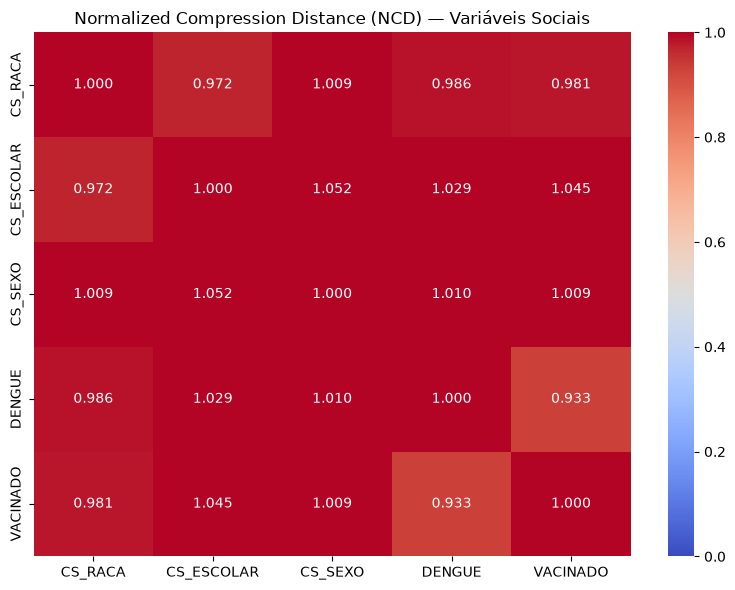

In [134]:
def compress_size(data):
    return len(zlib.compress(data, level=9))


def serialize_column(series):
    # Garante que a entrada seja uma Series
    if isinstance(series, pd.DataFrame):
        raise ValueError(
            "A coluna selecionada não é única. "
            "Verifique os nomes duplicados em df_social.columns."
        )

    values = series.astype("string").fillna("<AUSENTE>").tolist()

    return "\n".join(
        f"{len(value)}:{value}" for value in values
    ).encode("utf-8")


def ncd(x, y):
    bx = serialize_column(x)
    by = serialize_column(y)

    cx = compress_size(bx)
    cy = compress_size(by)

    combined = pd.Series(
        x.astype("string").fillna("<AUSENTE>").to_numpy()
        + "\t"
        + y.astype("string").fillna("<AUSENTE>").to_numpy()
    )

    cxy = compress_size(serialize_column(combined))

    denominador = max(cx, cy)

    if denominador == 0:
        return np.nan

    return (cxy - min(cx, cy)) / denominador

# Remover colunas duplicadas, mantendo a primeira ocorrência
df_social = df_social.loc[
    :, ~df_social.columns.duplicated()
].copy()

# Manter apenas as variáveis desejadas que existem no DataFrame
social_columns = [
    col for col in
    ['CS_RACA', 'CS_ESCOLAR', 'CS_SEXO', 'DENGUE', 'VACINADO']
    if col in df_social.columns
]

# Calcular matriz
n = len(social_columns)

ncd_matrix = pd.DataFrame(
    np.eye(n),
    index=social_columns,
    columns=social_columns
)

for i, col1 in enumerate(social_columns):
    for j in range(i + 1, n):
        col2 = social_columns[j]

        distance = ncd(
            df_social[col1],
            df_social[col2]
        )

        ncd_matrix.loc[col1, col2] = distance
        ncd_matrix.loc[col2, col1] = distance


# Visualizar
plt.figure(figsize=(8, 6))

sns.heatmap(
    ncd_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Normalized Compression Distance (NCD) — Variáveis Sociais")
plt.tight_layout()
plt.show()

In [135]:
def cramers_v(x, y):
    tabela = pd.crosstab(x, y)

    if min(tabela.shape) < 2:
        return np.nan

    n = tabela.to_numpy().sum()
    r, k = tabela.shape

    if n <= 1:
        return np.nan

    chi2 = chi2_contingency(tabela, correction=False)[0]
    phi2 = chi2 / n

    # Correção de viés
    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - (r - 1)**2 / (n - 1)
    k_corr = k - (k - 1)**2 / (n - 1)

    denom = min(k_corr - 1, r_corr - 1)

    if denom <= 0:
        return np.nan

    return np.sqrt(phi2_corr / denom)

def analisar_par(x, y):
    pares = pd.DataFrame({"x": x, "y": y}).dropna()

    tabela = pd.crosstab(pares["x"], pares["y"])

    if min(tabela.shape) < 2:
        return np.nan, np.nan, len(pares)

    _, p_valor, _, _ = chi2_contingency(
        tabela, correction=False
    )

    v = cramers_v(pares["x"], pares["y"])

    return v, p_valor, len(pares)

resultados = []

for a, b in combinations(social_columns, 2):
    v, p, n = analisar_par(df_social[a], df_social[b])

    resultados.append({
        "Variável 1": a,
        "Variável 2": b,
        "V de Cramér": v,
        "p-valor": p,
        "N": n
    })

resultados = pd.DataFrame(resultados)

# Corrigir os p-valores para múltiplos testes
validos = resultados["p-valor"].notna()

resultados["p-valor ajustado"] = np.nan
if validos.any():
    resultados.loc[validos, "p-valor ajustado"] = (
        multipletests(
            resultados.loc[validos, "p-valor"],
            method="fdr_bh"
        )[1]
    )

resultados = resultados.sort_values(
    "V de Cramér", ascending=False
)

display(resultados)


,Variável 1,Variável 2,V de Cramér,p-valor,N,p-valor ajustado
9,DENGUE,VACINADO,0.388399,0.000000e+00,7918,0.000000e+00
0,CS_RACA,CS_ESCOLAR,0.308460,0.000000e+00,7918,0.000000e+00
3,CS_RACA,VACINADO,0.218205,1.235714e-157,7918,4.119048e-157
6,CS_ESCOLAR,VACINADO,0.202188,4.847309e-132,7918,1.211827e-131
2,CS_RACA,DENGUE,0.156373,3.835523e-79,7918,7.671047e-79
5,CS_ESCOLAR,DENGUE,0.143188,1.008592e-63,7918,1.680986e-63
4,CS_ESCOLAR,CS_SEXO,0.053701,1.346459e-07,7918,1.923513e-07
8,CS_SEXO,VACINADO,0.038050,2.061024e-05,7918,2.576280e-05
1,CS_RACA,CS_SEXO,0.014251,2.118170e-01,7918,2.353523e-01
7,CS_SEXO,DENGUE,0.000000,5.762442e-01,7918,5.762442e-01


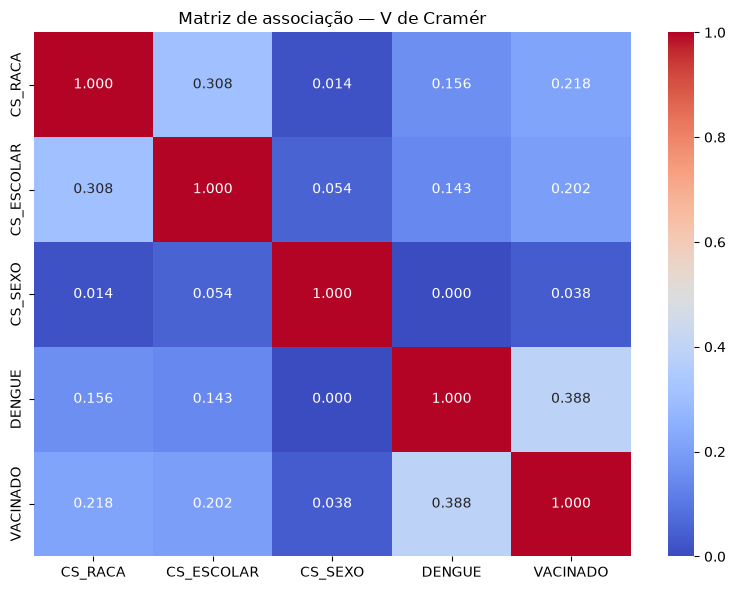

In [136]:
matriz_v = pd.DataFrame(
    np.eye(len(social_columns)),
    index=social_columns,
    columns=social_columns
)

for a, b in combinations(social_columns, 2):
    v = cramers_v(
        df_social[a].dropna().align(
            df_social[b].dropna(),
            join="inner"
        )[0],
        df_social[b].dropna().align(
            df_social[a].dropna(),
            join="inner"
        )[0]
    )

    matriz_v.loc[a, b] = v
    matriz_v.loc[b, a] = v

plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz_v,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=0,
    vmax=1
)

plt.title("Matriz de associação — V de Cramér")
plt.tight_layout()
plt.show()


In [137]:
def bootstrap_cramers_v(x, y, n_boot=500, seed=42):
    pares = pd.DataFrame({"x": x, "y": y}).dropna()

    if len(pares) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    valores = []

    for _ in range(n_boot):
        idx = rng.integers(0, len(pares), len(pares))
        amostra = pares.iloc[idx]

        v = cramers_v(amostra["x"], amostra["y"])

        if np.isfinite(v):
            valores.append(v)

    if len(valores) < 20:
        return cramers_v(pares["x"], pares["y"]), np.nan, np.nan

    estimativa = cramers_v(pares["x"], pares["y"])
    inferior, superior = np.quantile(valores, [0.025, 0.975])

    return estimativa, inferior, superior

ic_resultados = []

for a, b in combinations(social_columns, 2):
    estimativa, inferior, superior = bootstrap_cramers_v(
        df_social[a], df_social[b]
    )

    ic_resultados.append({
        "Variável 1": a,
        "Variável 2": b,
        "V de Cramér": estimativa,
        "IC 95% inferior": inferior,
        "IC 95% superior": superior
    })

ic_resultados = pd.DataFrame(ic_resultados)
display(ic_resultados.sort_values("V de Cramér", ascending=False))


,Variável 1,Variável 2,V de Cramér,IC 95% inferior,IC 95% superior
9,DENGUE,VACINADO,0.388399,0.365815,0.408788
0,CS_RACA,CS_ESCOLAR,0.308460,0.298734,0.319544
3,CS_RACA,VACINADO,0.218205,0.196207,0.241043
6,CS_ESCOLAR,VACINADO,0.202188,0.183495,0.225034
2,CS_RACA,DENGUE,0.156373,0.136819,0.185208
5,CS_ESCOLAR,DENGUE,0.143188,0.126482,0.166614
4,CS_ESCOLAR,CS_SEXO,0.053701,0.042226,0.101660
8,CS_SEXO,VACINADO,0.038050,0.025829,0.069473
1,CS_RACA,CS_SEXO,0.014251,0.000000,0.055488
7,CS_SEXO,DENGUE,0.000000,0.000000,0.033473


In [138]:
sintomas_columns = ['DENGUE', 'FEBRE', 'LACO', 'CEFALEIA', 'EXANTEMA', 'DOR', 'PROSTACAO', 'MIALGIA', 'NAUSEAS', 'ARTRALGIA', 'DIARREIA', 'EPISTAXE', 'PETEQUIAS', 'GENGIVO', 'METRO', 'HEMATURA', 'SANGRAM', 'ASCITE', 'PLEURAL', 'PERICARDI', 'ABDOMINAL', 'HEPATO', 'MIOCARDI', 'HIPOTENSAO', 'CHOQUE', 'HOSPITALIZ']
df_sintomas = df_sp[sintomas_columns]

In [139]:
def cramers_v(x, y):
    dados = pd.DataFrame({'x': x, 'y': y}).dropna()

    if len(dados) == 0:
        return np.nan, np.nan

    tabela = pd.crosstab(dados['x'], dados['y'])

    if min(tabela.shape) < 2:
        return np.nan, np.nan

    qui2, p_valor, _, _ = chi2_contingency(tabela)

    n = tabela.to_numpy().sum()
    phi2 = qui2 / n
    r, k = tabela.shape

    # Correção de viés
    phi2_corr = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominador = min(k_corr - 1, r_corr - 1)

    if denominador <= 0:
        return np.nan, p_valor

    v = np.sqrt(phi2_corr / denominador)

    return v, p_valor


resultados = []

for var1, var2 in combinations(sintomas_columns, 2):
    v, p = cramers_v(df_sintomas[var1], df_sintomas[var2])

    resultados.append({
        'Variável 1': var1,
        'Variável 2': var2,
        'V de Cramér': v,
        'p-valor': p
    })

df_associacoes = pd.DataFrame(resultados)

df_associacoes = df_associacoes.sort_values(
    'V de Cramér',
    ascending=False
)

display(df_associacoes.head(20))

,Variável 1,Variável 2,V de Cramér,p-valor
289,ASCITE,PLEURAL,0.802957,0.0
297,PLEURAL,PERICARDI,0.784339,0.0
270,HEMATURA,SANGRAM,0.778338,0.0
322,HIPOTENSAO,CHOQUE,0.777755,0.0
259,METRO,HEMATURA,0.776382,0.0
248,GENGIVO,HEMATURA,0.776198,0.0
247,GENGIVO,METRO,0.772577,0.0
221,EPISTAXE,GENGIVO,0.771019,0.0
260,METRO,SANGRAM,0.767679,0.0
315,HEPATO,MIOCARDI,0.767486,0.0


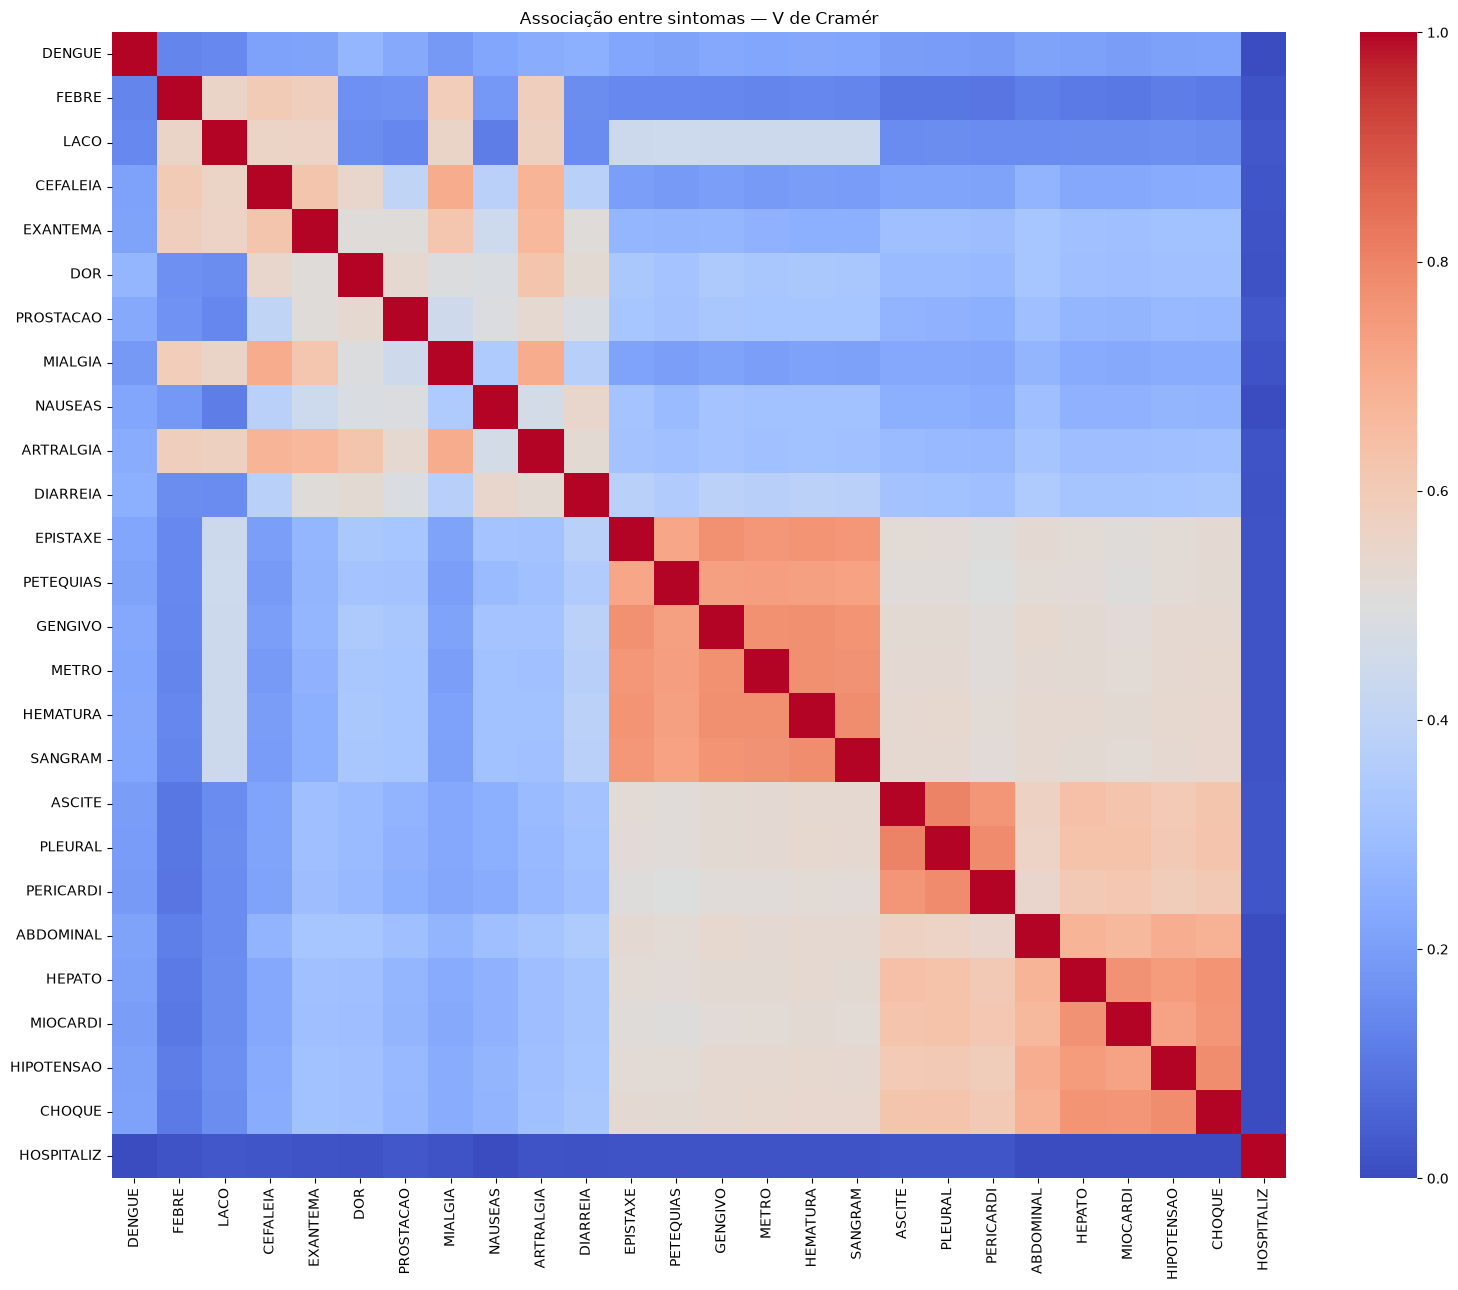

In [140]:
matriz_v = pd.DataFrame(
    np.eye(len(sintomas_columns)),
    index=sintomas_columns,
    columns=sintomas_columns
)

for _, row in df_associacoes.iterrows():
    a = row['Variável 1']
    b = row['Variável 2']
    matriz_v.loc[a, b] = row['V de Cramér']
    matriz_v.loc[b, a] = row['V de Cramér']

plt.figure(figsize=(16, 13))
sns.heatmap(
    matriz_v,
    cmap='coolwarm',
    vmin=0,
    vmax=1
)
plt.title('Associação entre sintomas — V de Cramér')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Correlações não lineares

In [141]:
def informacao_mutua_normalizada(x, y):
    dados = pd.DataFrame({'x': x, 'y': y}).dropna()

    if len(dados) == 0:
        return np.nan

    tabela = pd.crosstab(dados['x'], dados['y']).to_numpy(dtype=float)
    pxy = tabela / tabela.sum()
    px = pxy.sum(axis=1, keepdims=True)
    py = pxy.sum(axis=0, keepdims=True)

    mascara = pxy > 0
    denominador = px @ py

    mi = np.sum(
        pxy[mascara] *
        np.log(pxy[mascara] / denominador[mascara])
    )

    hx = -np.sum(px[px > 0] * np.log(px[px > 0]))
    hy = -np.sum(py[py > 0] * np.log(py[py > 0]))

    if hx == 0 or hy == 0:
        return np.nan

    return mi / np.sqrt(hx * hy)


def ncd(x, y):
    dados = pd.DataFrame({'x': x, 'y': y}).dropna()

    if len(dados) == 0:
        return np.nan

    # Serializa as duas variáveis usando a mesma amostra
    sx = '\n'.join(dados['x'].astype(str)).encode('utf-8')
    sy = '\n'.join(dados['y'].astype(str)).encode('utf-8')

    sxy = b'X:' + sx + b'\nY:' + sy

    cx = len(zlib.compress(sx))
    cy = len(zlib.compress(sy))
    cxy = len(zlib.compress(sxy))

    maior = max(cx, cy)

    if maior == 0:
        return np.nan

    return (cxy - min(cx, cy)) / maior

In [142]:
def calcular_associacoes_nao_lineares(df, colunas):
    resultados = []

    for var1, var2 in combinations(colunas, 2):
        x = df[var1]
        y = df[var2]

        resultados.append({
            'Variável 1': var1,
            'Variável 2': var2,
            'Informação mútua normalizada':
                informacao_mutua_normalizada(x, y),
            'NCD': ncd(x, y)
        })

    return pd.DataFrame(resultados)


# Variáveis sociais
resultados_sociais = calcular_associacoes_nao_lineares(
    df_social,
    social_columns
)

# Sintomas
resultados_sintomas = calcular_associacoes_nao_lineares(
    df_sintomas,
    sintomas_columns
)

In [143]:
print("SOCIAIS — maiores informações mútuas")
display(
    resultados_sociais
    .sort_values('Informação mútua normalizada', ascending=False)
    .head(15)
)

print("SINTOMAS — maiores informações mútuas")
display(
    resultados_sintomas
    .sort_values('Informação mútua normalizada', ascending=False)
    .head(20)
)

print("SOCIAIS — menores NCD")
display(
    resultados_sociais
    .sort_values('NCD', ascending=True)
    .head(15)
)

print("SINTOMAS — menores NCD")
display(
    resultados_sintomas
    .sort_values('NCD', ascending=True)
    .head(20)
)

SOCIAIS — maiores informações mútuas


,Variável 1,Variável 2,Informação mútua normalizada,NCD
9,DENGUE,VACINADO,0.142554,1.010341
0,CS_RACA,CS_ESCOLAR,0.133374,1.019041
3,CS_RACA,VACINADO,0.038917,0.994642
2,CS_RACA,DENGUE,0.031327,1.008768
6,CS_ESCOLAR,VACINADO,0.025868,1.018593
5,CS_ESCOLAR,DENGUE,0.021711,1.021057
4,CS_ESCOLAR,CS_SEXO,0.003245,1.037410
8,CS_SEXO,VACINADO,0.002168,1.014995
1,CS_RACA,CS_SEXO,0.001088,1.044325
7,CS_SEXO,DENGUE,0.000402,1.057962


SINTOMAS — maiores informações mútuas


,Variável 1,Variável 2,Informação mútua normalizada,NCD
259,METRO,HEMATURA,0.941908,0.992338
270,HEMATURA,SANGRAM,0.935896,0.992428
260,METRO,SANGRAM,0.933799,0.992657
247,GENGIVO,METRO,0.932610,0.993772
248,GENGIVO,HEMATURA,0.932327,0.993327
249,GENGIVO,SANGRAM,0.922682,0.993105
223,EPISTAXE,HEMATURA,0.916408,0.994797
222,EPISTAXE,METRO,0.914964,0.995014
221,EPISTAXE,GENGIVO,0.909116,0.992196
224,EPISTAXE,SANGRAM,0.907563,0.994364


SOCIAIS — menores NCD


,Variável 1,Variável 2,Informação mútua normalizada,NCD
3,CS_RACA,VACINADO,0.038917,0.994642
2,CS_RACA,DENGUE,0.031327,1.008768
9,DENGUE,VACINADO,0.142554,1.010341
8,CS_SEXO,VACINADO,0.002168,1.014995
6,CS_ESCOLAR,VACINADO,0.025868,1.018593
0,CS_RACA,CS_ESCOLAR,0.133374,1.019041
5,CS_ESCOLAR,DENGUE,0.021711,1.021057
4,CS_ESCOLAR,CS_SEXO,0.003245,1.037410
1,CS_RACA,CS_SEXO,0.001088,1.044325
7,CS_SEXO,DENGUE,0.000402,1.057962


SINTOMAS — menores NCD


,Variável 1,Variável 2,Informação mútua normalizada,NCD
289,ASCITE,PLEURAL,0.860310,0.881425
320,MIOCARDI,CHOQUE,0.792967,0.886390
297,PLEURAL,PERICARDI,0.851186,0.895575
290,ASCITE,PERICARDI,0.803504,0.917640
315,HEPATO,MIOCARDI,0.757858,0.943057
317,HEPATO,CHOQUE,0.735028,0.945554
322,HIPOTENSAO,CHOQUE,0.707608,0.952936
316,HEPATO,HIPOTENSAO,0.622148,0.955625
319,MIOCARDI,HIPOTENSAO,0.649544,0.959211
306,PERICARDI,MIOCARDI,0.534337,0.961650


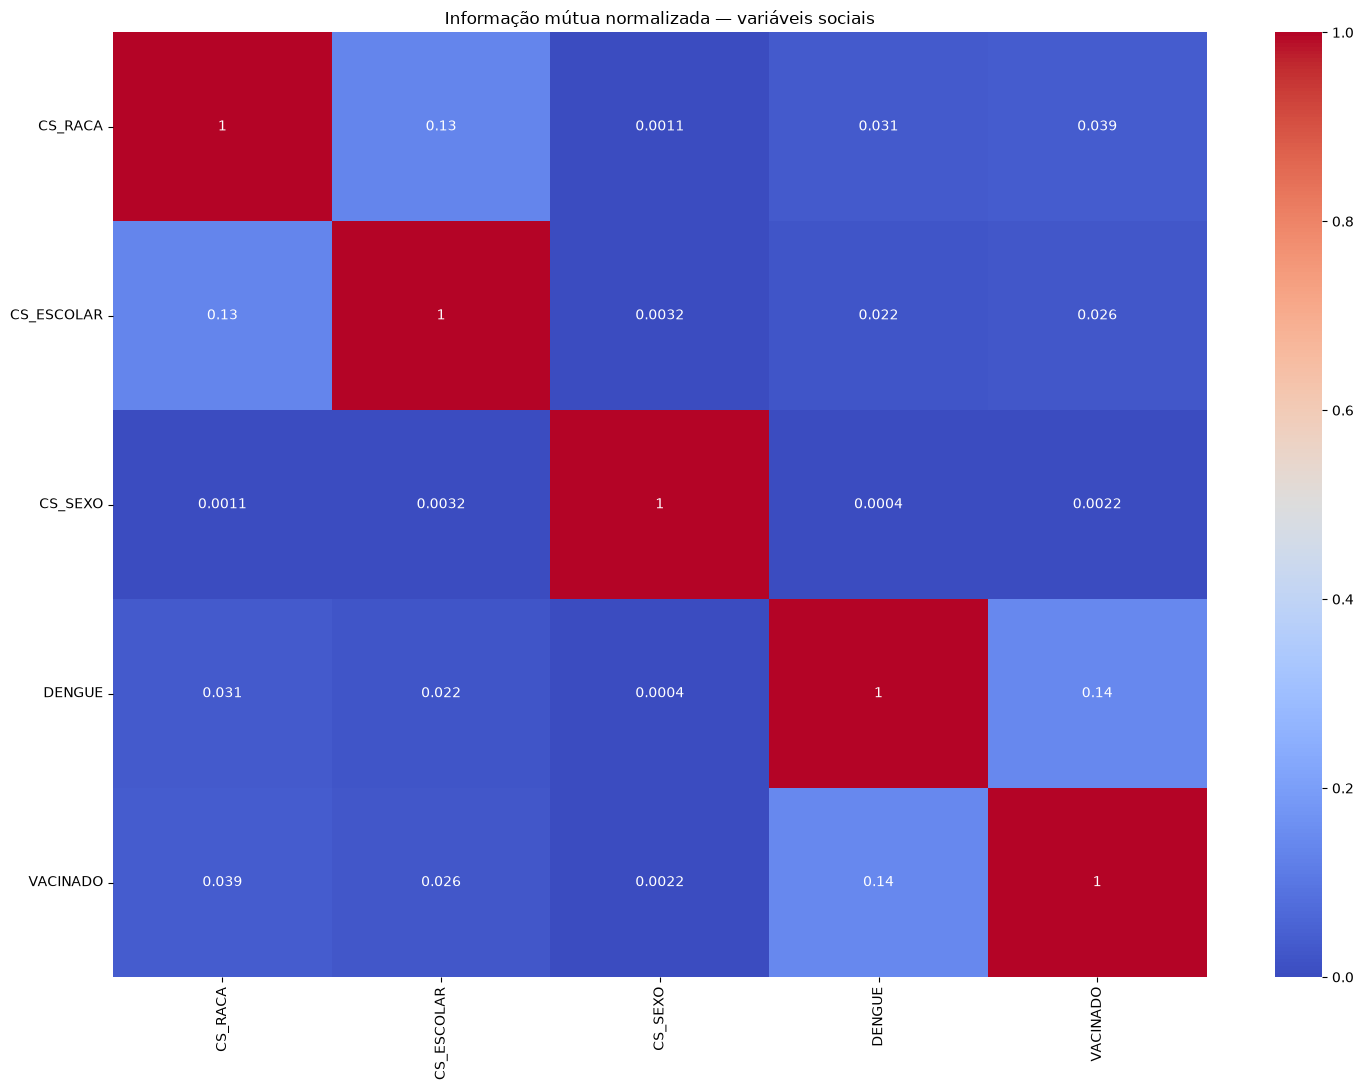

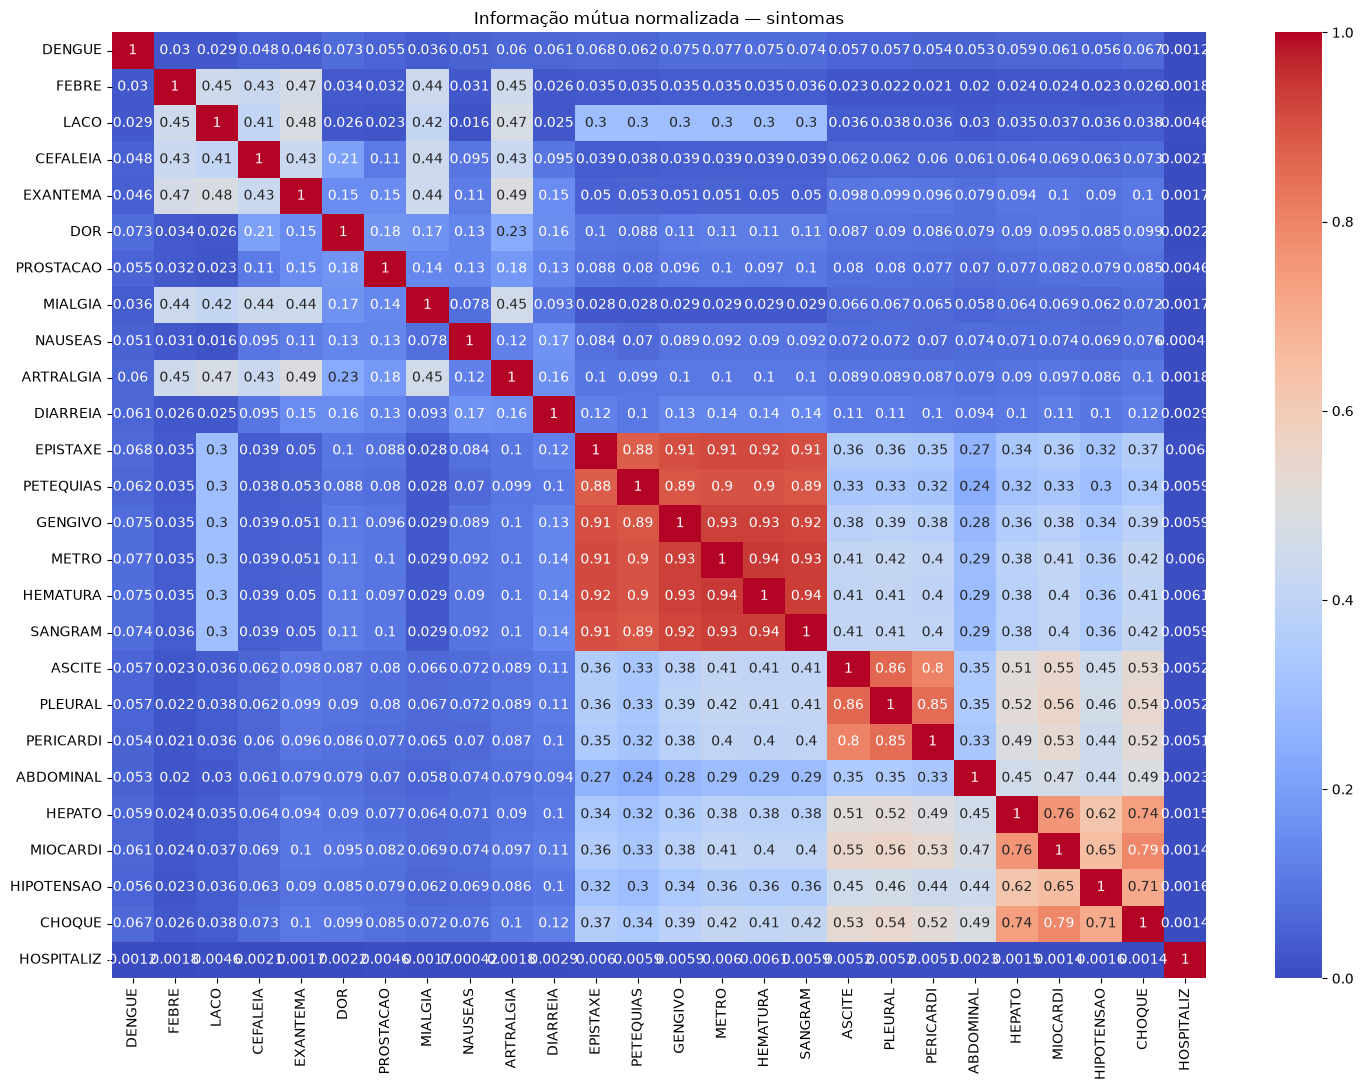

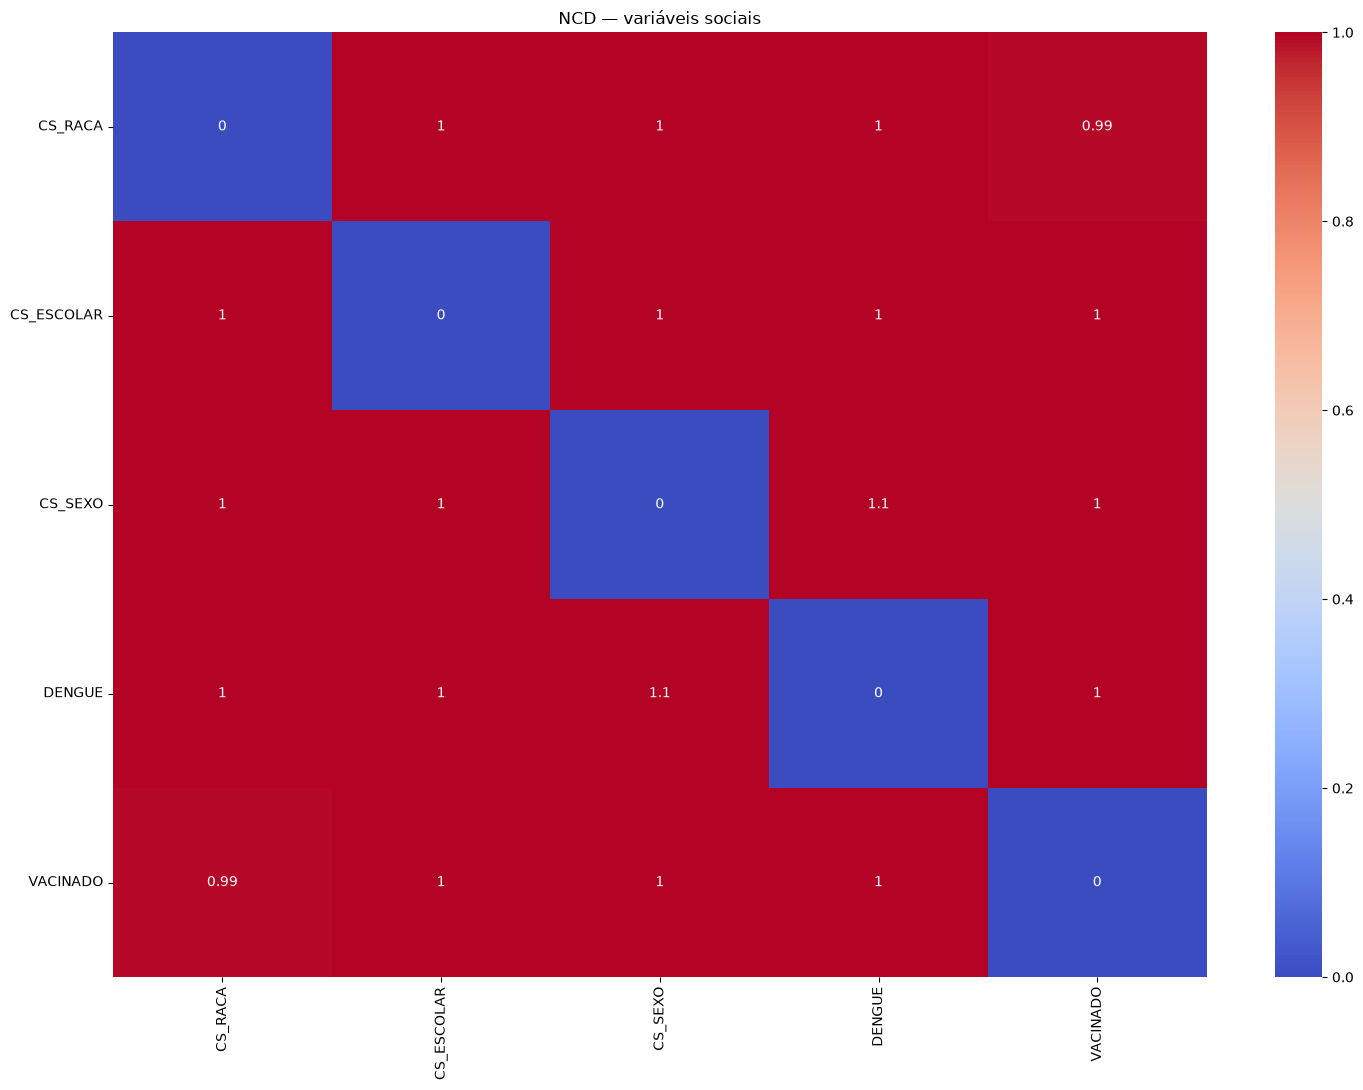

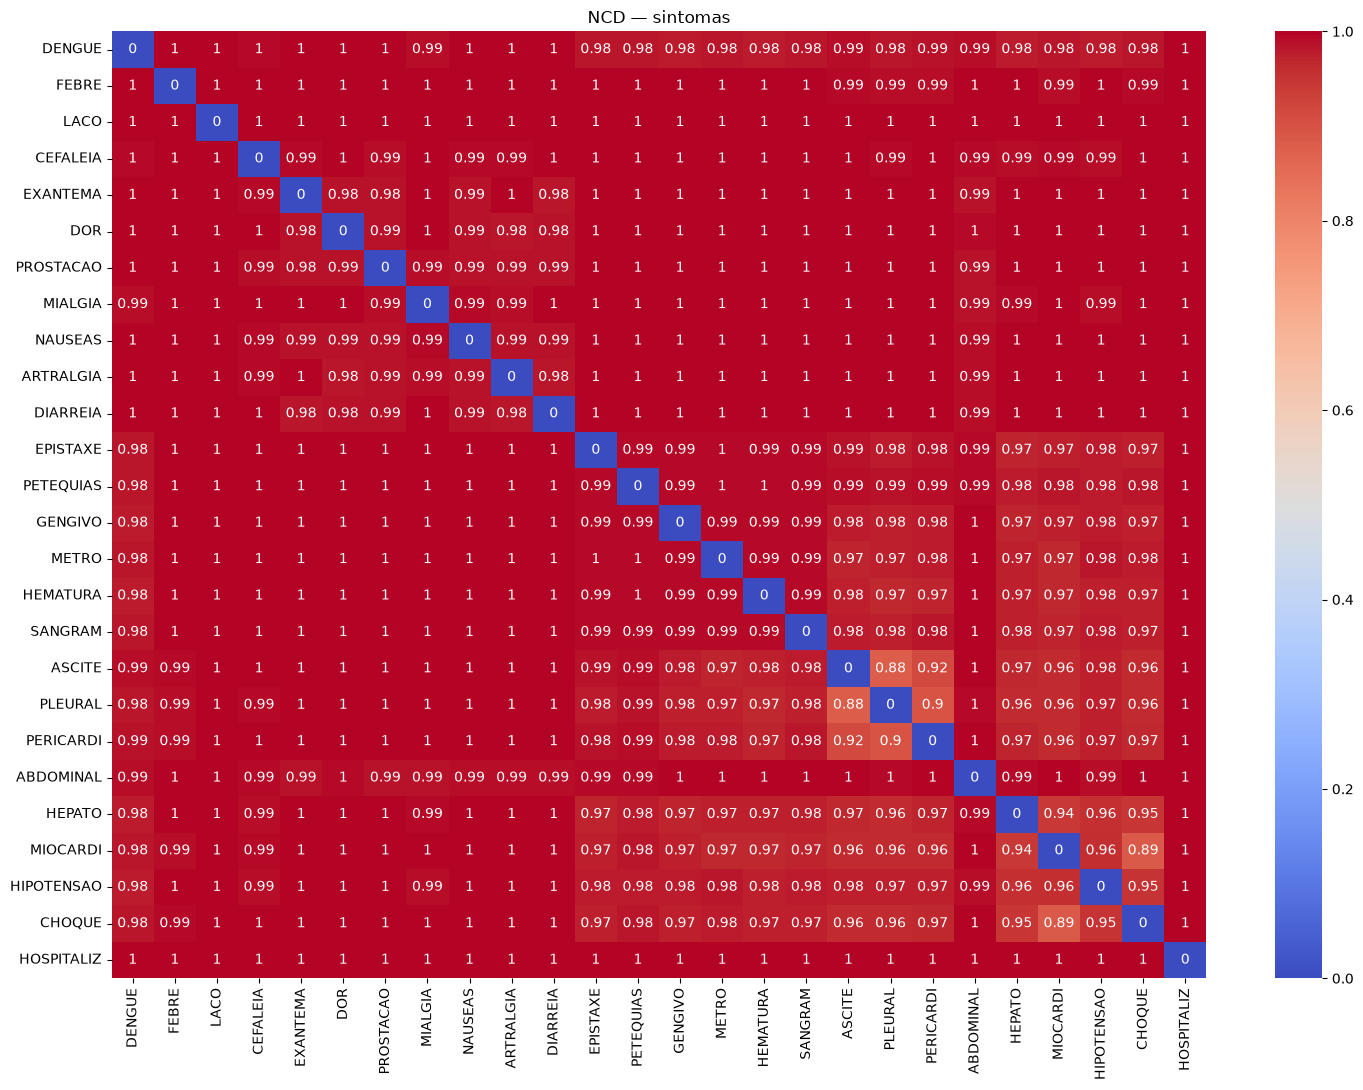

In [144]:
def plotar_matriz_associacao(df, colunas, funcao, titulo, cmap):
    matriz = pd.DataFrame(
        np.eye(len(colunas)) if funcao == 'MI'
        else np.zeros((len(colunas), len(colunas))),
        index=colunas,
        columns=colunas
    )

    for a, b in combinations(colunas, 2):
        valor = (
            informacao_mutua_normalizada(df[a], df[b])
            if funcao == 'MI'
            else ncd(df[a], df[b])
        )

        matriz.loc[a, b] = valor
        matriz.loc[b, a] = valor

    plt.figure(figsize=(15, 11))
    sns.heatmap(
        matriz,
        cmap=cmap,
        annot=True,
        vmin=0,
        vmax=1
    )
    plt.title(titulo)
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return matriz


# Informação mútua normalizada
mi_social = plotar_matriz_associacao(
    df_social, social_columns, 'MI',
    'Informação mútua normalizada — variáveis sociais',
    'coolwarm'
)

mi_sintomas = plotar_matriz_associacao(
    df_sintomas, sintomas_columns, 'MI',
    'Informação mútua normalizada — sintomas',
    'coolwarm'
)

# NCD
ncd_social = plotar_matriz_associacao(
    df_social, social_columns, 'NCD',
    'NCD — variáveis sociais',
    'coolwarm'
)

ncd_sintomas = plotar_matriz_associacao(
    df_sintomas, sintomas_columns, 'NCD',
    'NCD — sintomas',
    'coolwarm'
)